In [1]:
# ENTROPY COMPARISON
import pandas as pd, numpy as np
import os
from os import listdir
from os.path import isfile, join

os.chdir("..")

def get_all_files(mypath):
    onlyfiles = [join(mypath, f) for f in listdir(mypath) if isfile(join(mypath, f))]
    return onlyfiles

base_parquet_df = pd.read_parquet("data/eval_results/single_eval/Qwen2.5-14B_20250505T233200/results.parquet")
# e.g. plot average entropy per layer across correct answers
all_layers_ent = []
all_layers_lp = []
for _, row in base_parquet_df[base_parquet_df.correct].iterrows():
    data = np.load(row.tensor_path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
base_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
base_lp_df = pd.DataFrame(all_layers_lp)

all_layers_ent = []
all_layers_lp = []
for path in get_all_files("data/eval_results/single_eval/DeepSeek-R1-Distill-Qwen-14B_20250505T233229/tensors"): # There's no way of getting which ones are correct in here
    data = np.load(path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
R1_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
R1_lp_df = pd.DataFrame(all_layers_lp)

all_layers_ent = []
all_layers_lp = []
for path in get_all_files("data/eval_results/single_eval/checkpoint-1500_20250505T233234/tensors"): # There's no way of getting which ones are correct in here
    data = np.load(path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
GRPO_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
GRPO_lp_df = pd.DataFrame(all_layers_lp)

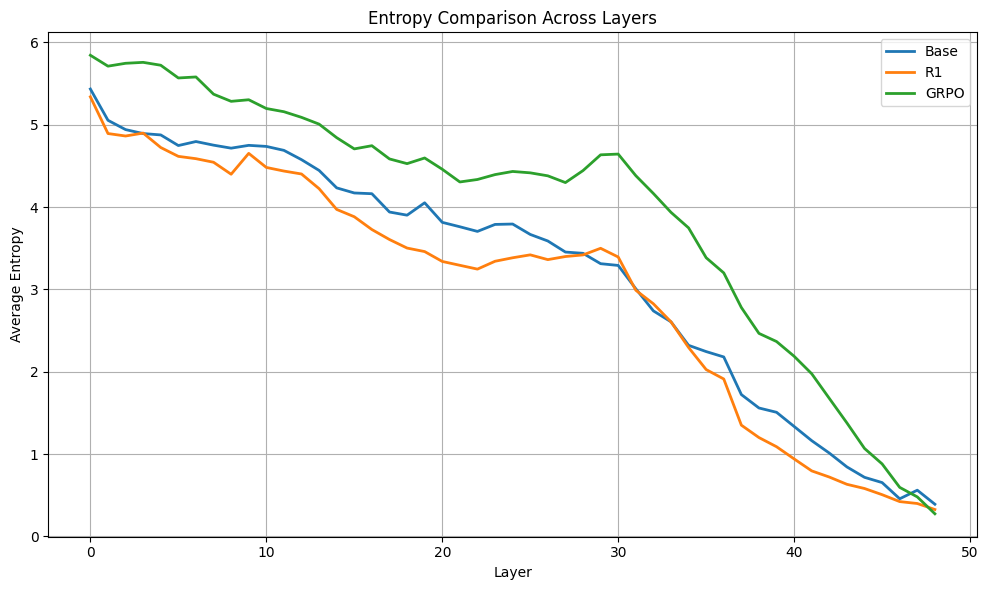

In [2]:
import matplotlib.pyplot as plt

# Compute means
base_mean = base_ent_df.mean()
R1_mean = R1_ent_df.mean()
GRPO_mean = GRPO_ent_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Entropy")
plt.title("Entropy Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


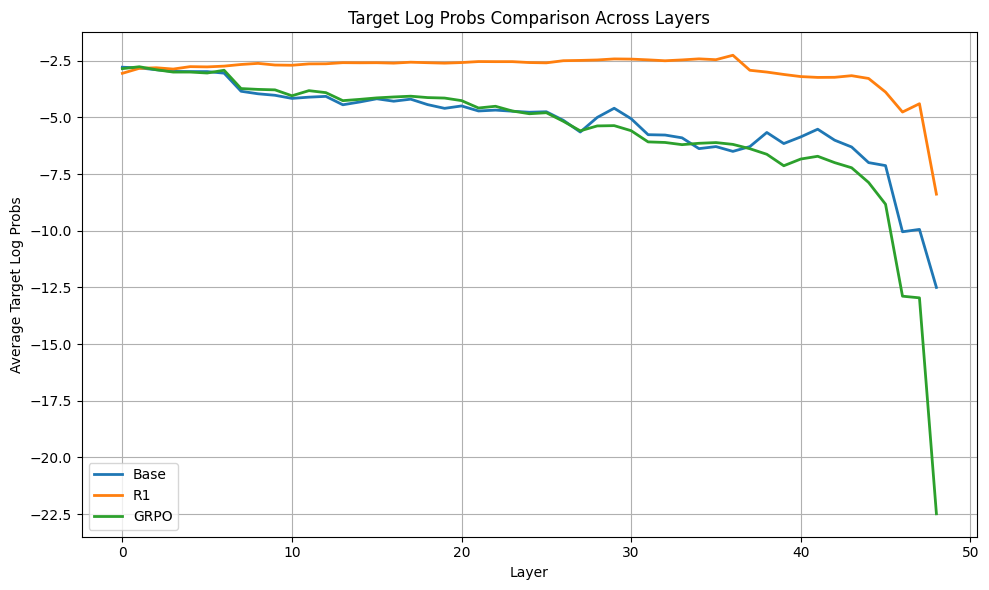

In [3]:
# Compute means
base_mean = base_lp_df.mean()
R1_mean = R1_lp_df.mean()
GRPO_mean = GRPO_lp_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
base_df = pd.read_parquet("data/eval_results/single_eval/Qwen2.5-14B_20250505T233200/results.parquet")
R1_df = 

# e.g. plot average entropy per layer across correct answers
all_layers = []
for _, row in df[df.correct].iterrows():
    ent = np.load(row.tensor_path)["entropy"]
    all_layers.append(ent.mean(axis=1))          # (num_layers,)
layer_df = pd.DataFrame(all_layers)              # shape: n × num_layers
layer_df.mean().plot()     

<Axes: >

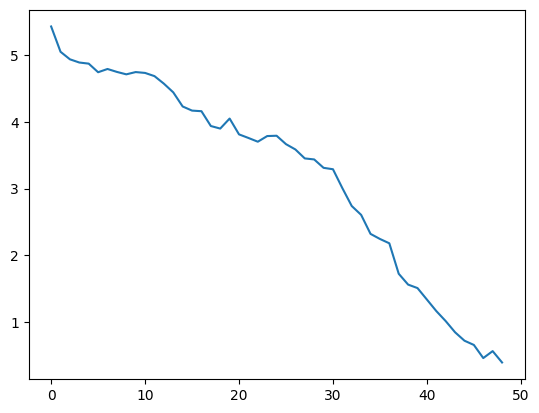

In [2]:
import pandas as pd, numpy as np
import os

os.chdir("..")

df = pd.read_parquet("data/eval_results/single_eval/Qwen2.5-14B_20250505T233200/results.parquet")

# e.g. plot average entropy per layer across correct answers
all_layers = []
for _, row in df[df.correct].iterrows():
    ent = np.load(row.tensor_path)["entropy"]
    all_layers.append(ent.mean(axis=1))          # (num_layers,)
layer_df = pd.DataFrame(all_layers)              # shape: n × num_layers
layer_df.mean().plot()                           # simple example


<Axes: >

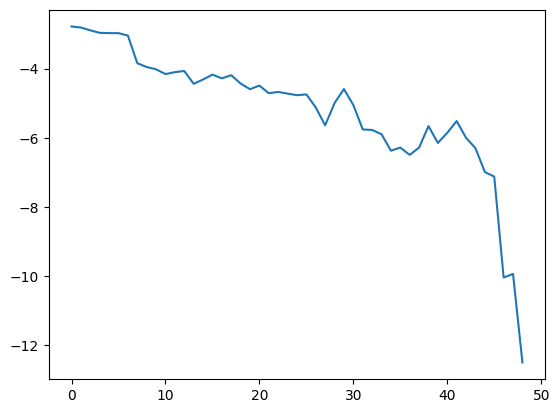

In [8]:
# e.g. plot average entropy per layer across correct answers
all_layers = []
for _, row in df[df.correct].iterrows():
    log_probs = np.load(row.tensor_path)["log_probs"]
    all_layers.append(log_probs)          # (num_layers,)
layer_df = pd.DataFrame(all_layers)              # shape: n × num_layers
layer_df.mean().plot()                           # simple example

In [5]:
log_probs

array([ -3.0117188,  -3.0751953,  -3.1328125,  -3.2421875,  -3.180664 ,
        -3.1191406,  -3.203125 ,  -4.0664062,  -3.9697266,  -3.9580078,
        -4.404297 ,  -4.2001953,  -4.341797 ,  -4.5185547,  -4.368164 ,
        -4.5185547,  -4.7958984,  -4.7890625,  -5.1640625,  -5.5097656,
        -4.9970703,  -5.5859375,  -5.573242 ,  -5.8876953,  -5.9160156,
        -5.9873047,  -6.385742 ,  -7.1621094,  -6.0976562,  -5.2402344,
        -5.5283203,  -6.7402344,  -7.189453 ,  -6.6914062,  -6.9697266,
        -7.211914 ,  -7.3867188,  -7.1152344,  -6.4404297,  -6.517578 ,
        -5.838867 ,  -5.21875  ,  -5.3378906,  -5.7822266,  -6.0117188,
        -6.1035156, -10.214844 , -11.609375 , -13.6171875], dtype=float32)

In [6]:
row

id                                                                      1318
question                   Henry and 3 of his friends order 7 pizzas for ...
ground_answer_text         There are 7*8=<<7*8=56>>56 slices in total.\nT...
model_answers_text         [There are 4 people in total, and they have 7 ...
extracted_model_answers                                                 [14]
extracted_ground_answer                                                   14
majority_answer                                                           14
correct                                                                 True
tensor_path                data/eval_results/single_eval/Qwen2.5-14B_2025...
Name: 1318, dtype: object

In [3]:
df.columns

Index(['id', 'question', 'ground_answer_text', 'model_answers_text',
       'extracted_model_answers', 'extracted_ground_answer', 'majority_answer',
       'correct', 'tensor_path'],
      dtype='object')